                  q99  q999  temp/10a  máx f     ξ   Hs2 Hs2 dentro  Hs10 Hs10 dentro  Hs50 Hs50 dentro  Hs100 Hs100 dentro
punto ruido                                                                                                                
p49   observado  2.64  3.73     62.44    NaN  0.16  3.81        NaN  4.80         NaN  5.95         NaN   6.53          NaN
      completo   2.70  3.89     59.94   2.20 -0.08  3.99          ✓  4.88           ✓  5.58           ✓   5.85            ✓
      simple     2.71  3.92     60.58   2.30 -0.14  3.99          ✓  4.92           ✓  5.56           ✓   5.82            ✓
p102  observado  3.73  5.30     62.20    NaN -0.13  5.59        NaN  6.67         NaN  7.43         NaN   7.70          NaN
      completo   3.89  5.72     60.41   2.27 -0.17  5.79          ✓  7.05           ✓  7.89           ✓   8.18            ✓
      simple     3.92  5.75     60.81   2.36 -0.18  5.80          ✓  7.06           ✗  7.93           ✓   8.22            ✓

sesgo d

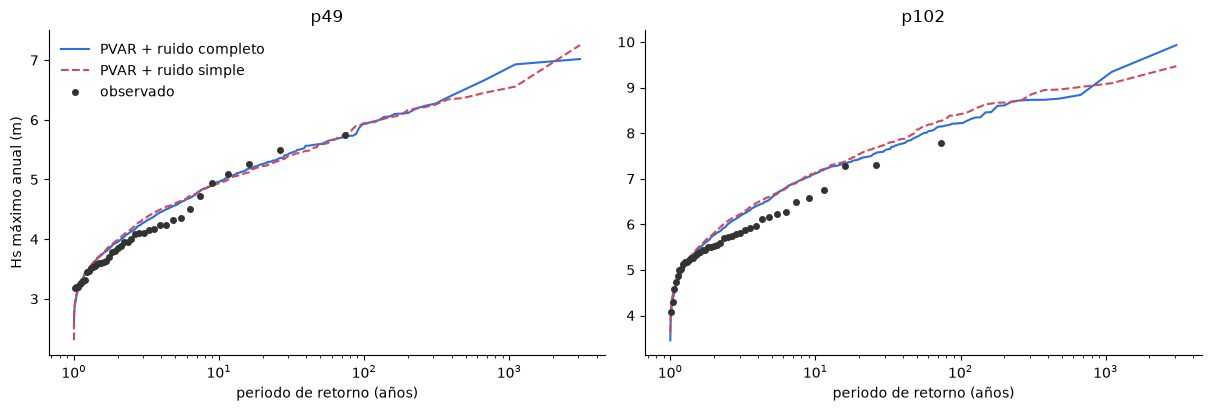

In [2]:
#### Comparación final: 2 puntos × 2 modelos de ruido (lee los am_pvar*.pkl del 08)
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.signal import find_peaks

PUNTOS = ["p49", "p102"]
RUIDOS = {"completo": "", "simple": "_simple"}
T_RET = [2, 10, 50, 100]

def gev_niveles(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_RET}}

def gringorten(am):
    am = np.sort(np.asarray(am)); n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

filas, curvas = [], {}
for pt in PUNTOS:
    hs_obs = pd.read_csv(f"inputs/waves_bulk_{pt}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"]
    am_obs = hs_obs.groupby(hs_obs.index.year).max()
    u = hs_obs.quantile(0.99)
    g_obs = gev_niveles(am_obs.values)
    filas.append({"punto": pt, "ruido": "observado", "q99": hs_obs.quantile(0.99), "q999": hs_obs.quantile(0.999),
                  "temp/10a": len(find_peaks(hs_obs.values, height=u, distance=72)[0]) * 10 / 41, **g_obs})
    curvas[(pt, "observado")] = gringorten(am_obs)
    for nombre, suf in RUIDOS.items():
        try:
            d = pickle.load(open(f"outputs/xgb_pit_{pt}/am_pvar{suf}.pkl", "rb"))
        except FileNotFoundError:
            print(f"falta {pt} {nombre}"); continue
        am_hs, st = d["am_hs"], d["stats"]
        n_b = len(am_obs)
        bloques = [am_hs[c].values[j:j + n_b] for c in am_hs.columns for j in range(0, len(am_hs) - n_b + 1, n_b)]
        g = pd.DataFrame([gev_niveles(b) for b in bloques])
        fila = {"punto": pt, "ruido": nombre, "q99": st["q99"].median(), "q999": st["q999"].median(),
                "temp/10a": st["temporales/10 años"].median(), "máx f": d["am_f"].values.mean()}
        for k in ["ξ"] + [f"Hs{t}" for t in T_RET]:
            lo, med, hi = g[k].quantile([0.025, 0.5, 0.975])
            fila[k] = med
            if k != "ξ":
                fila[f"{k} dentro"] = "✓" if lo <= g_obs[k] <= hi else "✗"
        filas.append(fila)
        curvas[(pt, nombre)] = gringorten(am_hs.values.ravel())

tabla = pd.DataFrame(filas).set_index(["punto", "ruido"])
cols = ["q99", "q999", "temp/10a", "máx f", "ξ"] + sum([[f"Hs{t}", f"Hs{t} dentro"] for t in T_RET], [])
print(tabla[[c for c in cols if c in tabla]].round(2).to_string())

#### Sesgo de la mediana frente a lo observado (%)
sesgo = pd.DataFrame({(pt, r): {f"Hs{t}": 100 * (tabla.loc[(pt, r), f"Hs{t}"] / tabla.loc[(pt, "observado"), f"Hs{t}"] - 1) for t in T_RET}
                      for pt, r in tabla.index if r != "observado"}).T
print("\nsesgo de la mediana (%)"); print(sesgo.round(1).to_string())

#### Curvas de periodo de retorno
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
estilo = {"completo": dict(color="#2a6fdb", lw=1.5), "simple": dict(color="#d1495b", lw=1.5, ls="--")}
for ax, pt in zip(axs, PUNTOS):
    for nombre in RUIDOS:
        if (pt, nombre) in curvas:
            ax.plot(*curvas[(pt, nombre)], label=f"PVAR + ruido {nombre}", **estilo[nombre])
    ax.plot(*curvas[(pt, "observado")], "o", color="0.2", ms=4, label="observado")
    ax.set(xscale="log", title=pt, xlabel="periodo de retorno (años)")
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("Hs máximo anual (m)")
axs[0].legend(frameon=False, loc="upper left")
plt.show()